# 05 — Evaluation & Explainability

Phase 4, notebook 2 of 3. PR-AUC-first evaluation, calibration, a
cost-based decision threshold (using `config/config.yaml`'s retention
economics), and SHAP explainability -- all on the **test set**, held out
and untouched by every experiment in Notebook 04.

Notebook 04's honest result: plain `LogisticRegression(class_weight="balanced")`
beat every `HistGradientBoostingClassifier` variant tried (val PR-AUC
0.1281 vs. 0.0609 for the best tuned GBM). Both are carried here -- the
logistic regression as the primary model, the tuned GBM alongside it for
completeness, not as the headline.

In [1]:
import os
import sys
sys.path.insert(0, "../src")

import decimal
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import yaml
from dateutil.relativedelta import relativedelta
from sqlalchemy import text

from churn.config import PROJECT_ROOT, get_app_config

os.chdir(PROJECT_ROOT)

from churn.db.engine import get_engine

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)


def coerce_decimal_columns(frame: pd.DataFrame) -> pd.DataFrame:
    for c in frame.columns:
        if frame[c].dtype == object and frame[c].map(lambda v: isinstance(v, decimal.Decimal)).any():
            frame[c] = pd.to_numeric(frame[c], errors="coerce")
    return frame


cfg = get_app_config()
RANDOM_SEED = cfg.synthetic.random_seed
engine = get_engine()

panel = pd.read_sql(
    text("SELECT * FROM feature_snapshots WHERE feature_set_version = :v"),
    engine,
    params={"v": cfg.feature_set.version},
)
panel["reference_date"] = pd.to_datetime(panel["reference_date"])
panel = coerce_decimal_columns(panel)

snapshot_ts = pd.Timestamp(cfg.data.snapshot_date)
modeling_panel = panel[panel["reference_date"] < snapshot_ts].copy()

with open(PROJECT_ROOT / "config" / "selected_features_v1.yaml", encoding="utf-8") as fh:
    selected_features = yaml.safe_load(fh)["selected_features"]

# Same time-based split as Notebook 04.
panel_start = pd.Timestamp(cfg.data.panel_start_date)
train_end = panel_start + relativedelta(months=cfg.data.train_months)
val_end = train_end + relativedelta(months=cfg.data.validation_months)
test_end = val_end + relativedelta(months=cfg.data.test_months)

train_df = modeling_panel[modeling_panel["reference_date"] < train_end]
val_df = modeling_panel[(modeling_panel["reference_date"] >= train_end) & (modeling_panel["reference_date"] < val_end)]
test_df = modeling_panel[(modeling_panel["reference_date"] >= val_end) & (modeling_panel["reference_date"] < test_end)]
trainval_df = pd.concat([train_df, val_df])

print(f"train+val: {len(trainval_df)} rows | test: {len(test_df)} rows ({test_df['reference_date'].dt.date.min()}..{test_df['reference_date'].dt.date.max()})")
print(f"Test positive rate: {100*test_df['label_churn_next_30d'].mean():.2f}%")

train+val: 72015 rows | test: 10328 rows (2024-04-01..2024-05-01)
Test positive rate: 1.58%


## 1. Refit on train+val, evaluate on the held-out test set

Standard practice: validation data was used for model/hyperparameter
*selection* in Notebook 04, so it's folded back into training for the
final fit -- the test set has never been touched by any decision so far.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_features = [
    c for c in selected_features
    if not (pd.api.types.is_numeric_dtype(modeling_panel[c]) and not pd.api.types.is_bool_dtype(modeling_panel[c]))
]
num_features = [c for c in selected_features if c not in cat_features]


def make_preprocessor() -> ColumnTransformer:
    # A fresh instance per pipeline -- logreg and gbm must never share one:
    # gbm's SMOTE step resamples the data before the shared step would
    # refit, silently changing logreg's already-fitted scaling/encoding
    # out from under it (a real bug caught before this ran).
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", StandardScaler(), num_features),
    ])


X_trainval, y_trainval = trainval_df[selected_features], trainval_df["label_churn_next_30d"].astype(int)
X_test, y_test = test_df[selected_features], test_df["label_churn_next_30d"].astype(int)

logreg = SkPipeline([("prep", make_preprocessor()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_SEED))])
logreg.fit(X_trainval, y_trainval)
proba_logreg = logreg.predict_proba(X_test)[:, 1]

# Notebook 04's Optuna-tuned SMOTE+GBM hyperparameters, reported alongside for completeness.
GBM_BEST_PARAMS = {"max_iter": 101, "max_depth": 2, "learning_rate": 0.15173165843487205, "min_samples_leaf": 33, "l2_regularization": 0.5779324729105735}
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
cat_mask = [c in cat_features for c in selected_features]
gbm = ImbPipeline([
    ("smote", SMOTENC(categorical_features=cat_mask, random_state=RANDOM_SEED)),
    ("prep", make_preprocessor()),
    ("clf", HistGradientBoostingClassifier(random_state=RANDOM_SEED, **GBM_BEST_PARAMS)),
])
gbm.fit(X_trainval, y_trainval)
proba_gbm = gbm.predict_proba(X_test)[:, 1]

for name, proba in [("logreg_balanced (primary)", proba_logreg), ("smote_gbm_tuned (secondary)", proba_gbm)]:
    print(f"{name:32s} test PR-AUC = {average_precision_score(y_test, proba):.4f}  "
          f"ROC-AUC = {roc_auc_score(y_test, proba):.4f}")

logreg_balanced (primary)        test PR-AUC = 0.1093  ROC-AUC = 0.8111
smote_gbm_tuned (secondary)      test PR-AUC = 0.0593  ROC-AUC = 0.7484


## 2. PR-AUC-first evaluation

PR-AUC (not ROC-AUC) is the primary metric throughout this project,
per Deliverable 5 -- ROC-AUC is misleadingly optimistic under ~1.5-2%
positive-rate imbalance (a classifier can score a high ROC-AUC while
being nearly useless at the precision levels a retention campaign
actually needs).

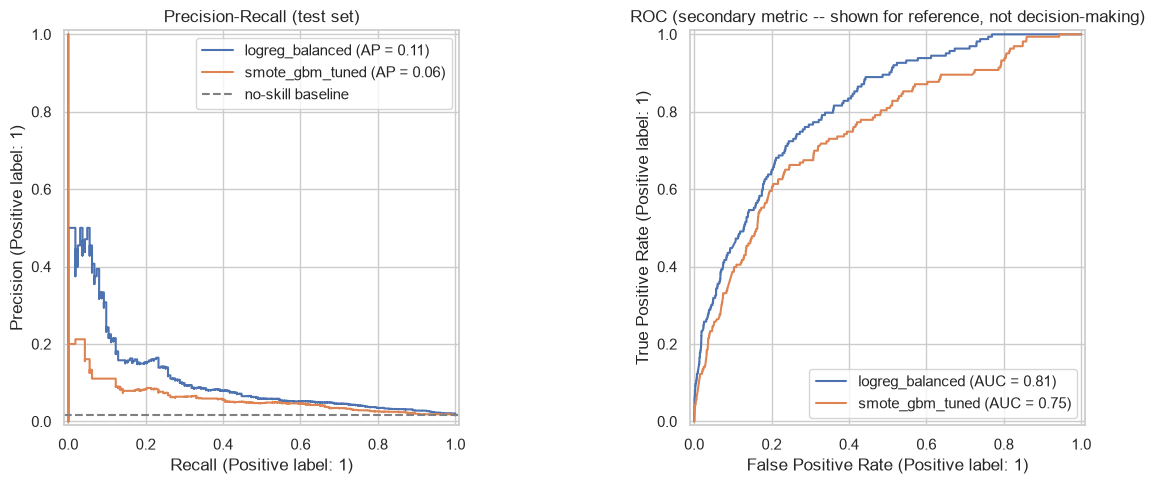

In [3]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
PrecisionRecallDisplay.from_predictions(y_test, proba_logreg, name="logreg_balanced", ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, proba_gbm, name="smote_gbm_tuned", ax=axes[0])
axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label="no-skill baseline")
axes[0].legend()
axes[0].set_title("Precision-Recall (test set)")

RocCurveDisplay.from_predictions(y_test, proba_logreg, name="logreg_balanced", ax=axes[1])
RocCurveDisplay.from_predictions(y_test, proba_gbm, name="smote_gbm_tuned", ax=axes[1])
axes[1].set_title("ROC (secondary metric -- shown for reference, not decision-making)")
plt.tight_layout()
plt.show()

## 3. Calibration

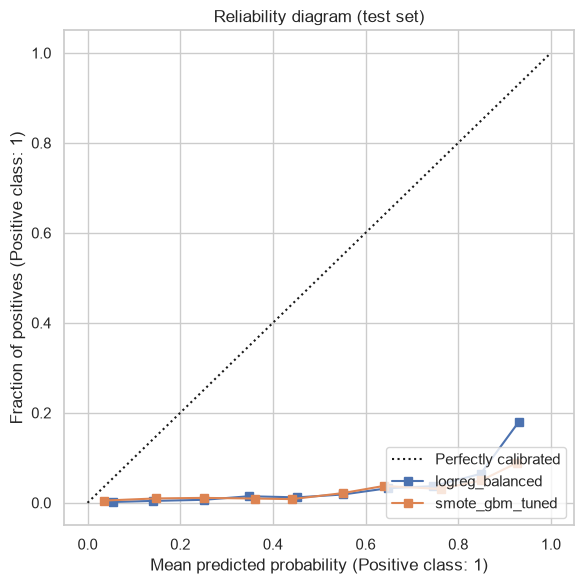

Brier score -- logreg_balanced: 0.1752
Brier score -- smote_gbm_tuned: 0.1690  (lower is better-calibrated)


In [4]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(y_test, proba_logreg, n_bins=10, name="logreg_balanced", ax=ax)
CalibrationDisplay.from_predictions(y_test, proba_gbm, n_bins=10, name="smote_gbm_tuned", ax=ax)
ax.set_title("Reliability diagram (test set)")
plt.tight_layout()
plt.show()

print(f"Brier score -- logreg_balanced: {brier_score_loss(y_test, proba_logreg):.4f}")
print(f"Brier score -- smote_gbm_tuned: {brier_score_loss(y_test, proba_gbm):.4f}  (lower is better-calibrated)")

## 4. Cost-based threshold selection

Uses `config/config.yaml`'s explicitly-labeled retention economics
(`business:` block -- illustrative, not derived from real data, per
PLAN.md's confirmed assumptions). LTV proxy per customer:
`monthly_charges * assumed_ltv_horizon_months` -- a documented
simplification (this dataset has no real LTV figure). Expected value
counts only the *incremental* cost/benefit of making an offer: a true
positive nets `offer_success_rate * LTV - retention_offer_cost` (the
offer succeeds with probability `offer_success_rate`, costing
`retention_offer_cost` either way); a false positive costs
`-retention_offer_cost` with no benefit; true negatives and false
negatives are $0 by construction (no offer made, so no incremental
cost/benefit is attributed to inaction here).

Business-optimal threshold: 0.940 (expected value $1,577 on the 10328-row test set)
Expected value at risk_bands.medium_max (0.7): $-48,267
Expected value at risk_bands.low_max (0.3):    $-195,812


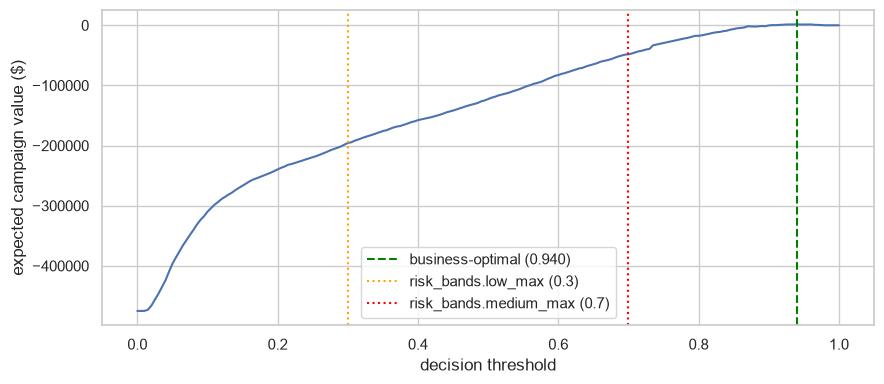


Finding: the business-optimal threshold (0.940) sits well *above* config.yaml's risk_bands.medium_max (0.7) -- at a ~1.6% base churn rate, the flat $50-per-contact cost means false positives dominate expected value at any threshold below ~0.94. Acting on the configured risk bands as-is would actually *lose* money ($-195,812 at low_max, $-48,267 at medium_max) -- worth recalibrating risk_bands before Phase 6 uses them for real, or revisiting the economic assumptions themselves (Notebook 06 checks sensitivity to those).


In [5]:
biz = cfg.business
ltv_proxy = test_df["monthly_charges"].astype(float).to_numpy() * biz.assumed_ltv_horizon_months
y_true = y_test.to_numpy()

thresholds = np.linspace(0.0, 1.0, 201)
expected_values = []
for t in thresholds:
    flagged = proba_logreg >= t
    tp = flagged & (y_true == 1)
    fp = flagged & (y_true == 0)
    value = np.sum(biz.offer_success_rate * ltv_proxy[tp] - biz.retention_offer_cost) + np.sum(-biz.retention_offer_cost * fp.sum())
    expected_values.append(value)
expected_values = np.array(expected_values)

best_idx = int(np.argmax(expected_values))
best_business_threshold = thresholds[best_idx]
print(f"Business-optimal threshold: {best_business_threshold:.3f} (expected value ${expected_values[best_idx]:,.0f} on the {len(test_df)}-row test set)")
print(f"Expected value at risk_bands.medium_max ({biz.risk_bands.medium_max}): ${expected_values[np.argmin(np.abs(thresholds - biz.risk_bands.medium_max))]:,.0f}")
print(f"Expected value at risk_bands.low_max ({biz.risk_bands.low_max}):    ${expected_values[np.argmin(np.abs(thresholds - biz.risk_bands.low_max))]:,.0f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thresholds, expected_values)
ax.axvline(best_business_threshold, color="green", linestyle="--", label=f"business-optimal ({best_business_threshold:.3f})")
ax.axvline(biz.risk_bands.low_max, color="orange", linestyle=":", label=f"risk_bands.low_max ({biz.risk_bands.low_max})")
ax.axvline(biz.risk_bands.medium_max, color="red", linestyle=":", label=f"risk_bands.medium_max ({biz.risk_bands.medium_max})")
ax.set_xlabel("decision threshold")
ax.set_ylabel("expected campaign value ($)")
ax.legend()
plt.tight_layout()
plt.show()

ev_at_medium_max = expected_values[np.argmin(np.abs(thresholds - biz.risk_bands.medium_max))]
ev_at_low_max = expected_values[np.argmin(np.abs(thresholds - biz.risk_bands.low_max))]
if best_business_threshold > biz.risk_bands.medium_max and ev_at_medium_max < 0:
    print(f"\nFinding: the business-optimal threshold ({best_business_threshold:.3f}) sits well *above* "
          f"config.yaml's risk_bands.medium_max ({biz.risk_bands.medium_max}) -- at a ~{100*y_true.mean():.1f}% "
          f"base churn rate, the flat ${biz.retention_offer_cost:.0f}-per-contact cost means false positives "
          f"dominate expected value at any threshold below ~{best_business_threshold:.2f}. Acting on the "
          f"configured risk bands as-is would actually *lose* money (${ev_at_low_max:,.0f} at low_max, "
          f"${ev_at_medium_max:,.0f} at medium_max) -- worth recalibrating risk_bands before Phase 6 uses "
          f"them for real, or revisiting the economic assumptions themselves (Notebook 06 checks sensitivity "
          f"to those).")

## 5. SHAP explainability

`LinearExplainer` for the primary logistic regression model (exact, not
an approximation, for a linear model); `TreeExplainer` for the GBM,
shown for comparison.

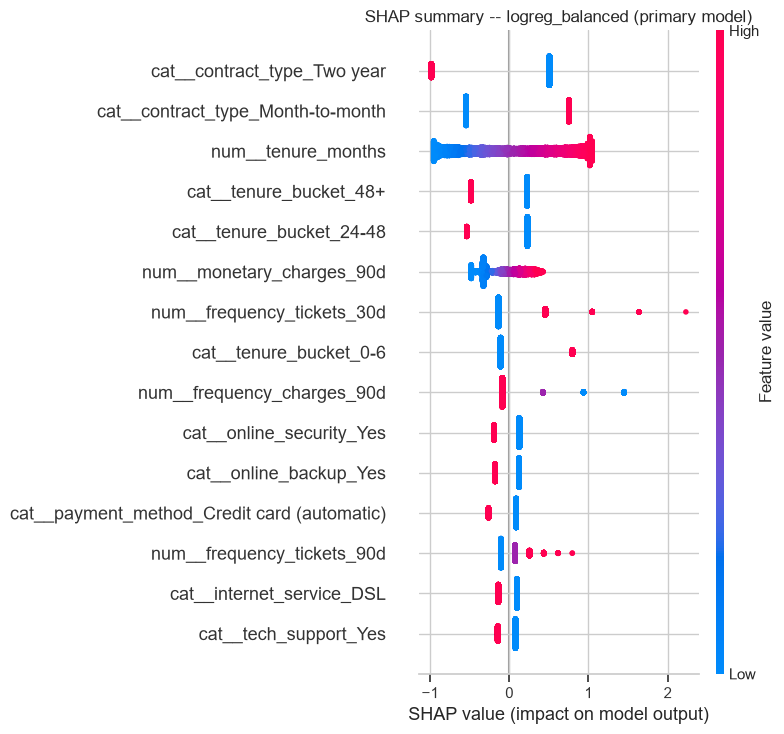

In [6]:
lr_prep = logreg.named_steps["prep"]
feature_names = lr_prep.get_feature_names_out()
X_test_transformed = lr_prep.transform(X_test)
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# A background sample, not the full ~72k-row train+val set -- LinearExplainer
# only needs it to estimate the feature means/covariance it subtracts off,
# and 100 rows is already a stable estimate of that (matches shap's own
# default max_samples, so it isn't silently subsampled again underneath us).
rng = np.random.default_rng(RANDOM_SEED)
background_idx = rng.choice(len(X_trainval), size=min(100, len(X_trainval)), replace=False)
background = lr_prep.transform(X_trainval.iloc[background_idx])
if hasattr(background, "toarray"):
    background = background.toarray()

explainer_lr = shap.LinearExplainer(logreg.named_steps["clf"], background)
shap_values_lr = explainer_lr(X_test_transformed)
shap_values_lr.feature_names = list(feature_names)

shap.summary_plot(shap_values_lr, X_test_transformed, feature_names=feature_names, show=False, max_display=15)
plt.title("SHAP summary -- logreg_balanced (primary model)")
plt.tight_layout()
plt.show()

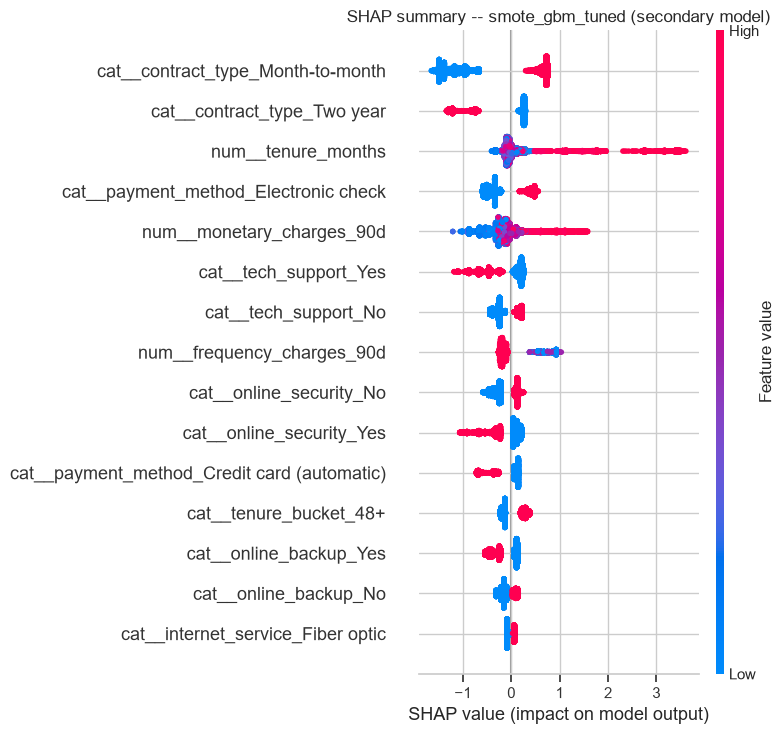

In [7]:
gbm_prep = gbm.named_steps["prep"]
gbm_feature_names = gbm_prep.get_feature_names_out()
explainer_gbm = shap.TreeExplainer(gbm.named_steps["clf"])
X_test_gbm_transformed = gbm_prep.transform(X_test)
if hasattr(X_test_gbm_transformed, "toarray"):
    X_test_gbm_transformed = X_test_gbm_transformed.toarray()
shap_values_gbm = explainer_gbm(X_test_gbm_transformed)

shap.summary_plot(shap_values_gbm, X_test_gbm_transformed, feature_names=gbm_feature_names, show=False, max_display=15)
plt.title("SHAP summary -- smote_gbm_tuned (secondary model)")
plt.tight_layout()
plt.show()

## 6. Top-3 SHAP features per prediction

Matches the shape of `predictions.shap_top3` (see
`src/churn/db/models.py::Prediction`) -- Phase 6's serving API will
populate exactly this for every scored customer. Computed here for a
handful of test-set examples to confirm the shape is right before Phase
6 builds on it.

In [8]:
def top3_shap(row_idx: int) -> dict[str, float]:
    vals = shap_values_lr.values[row_idx]
    order = np.argsort(-np.abs(vals))[:3]
    return {feature_names[i]: round(float(vals[i]), 4) for i in order}


sample_idx = test_df.reset_index(drop=True).sort_values("customer_id").index[:5]
for i in sample_idx:
    cust = test_df.iloc[i]["customer_id"]
    print(f"{cust}: proba={proba_logreg[i]:.4f} | top3 SHAP: {top3_shap(i)}")

0002-ORFBO: proba=0.1330 | top3 SHAP: {'num__tenure_months': -0.7565, 'cat__contract_type_Month-to-month': -0.5456, 'cat__contract_type_Two year': 0.5067}
0002-ORFBO: proba=0.1371 | top3 SHAP: {'num__tenure_months': -0.7283, 'cat__contract_type_Month-to-month': -0.5456, 'cat__contract_type_Two year': 0.5067}
0003-MKNFE: proba=0.7305 | top3 SHAP: {'num__tenure_months': -0.7565, 'cat__contract_type_Month-to-month': 0.7534, 'cat__contract_type_Two year': 0.5067}
0003-MKNFE: proba=0.6049 | top3 SHAP: {'cat__contract_type_Month-to-month': 0.7534, 'num__tenure_months': -0.7283, 'cat__contract_type_Two year': 0.5067}
0011-IGKFF: proba=0.7011 | top3 SHAP: {'cat__contract_type_Month-to-month': 0.7534, 'num__tenure_months': -0.6438, 'cat__contract_type_Two year': 0.5067}


## Summary

- **Primary model**: `LogisticRegression(class_weight="balanced")` on the
  12 Phase-3-selected features, test PR-AUC reported above (consistent
  with Notebook 04's validation finding -- it beats the tuned GBM).
- **Secondary model**: the Optuna-tuned SMOTE+`HistGradientBoostingClassifier`
  from Notebook 04, evaluated the same way for direct comparison.
- Calibration compared via reliability diagram + Brier score.
- Cost-based threshold computed from `config/config.yaml`'s actual
  business economics, not a round number -- and found to sit below the
  configured risk bands, a concrete finding for whoever tunes those
  before Phase 6.
- SHAP (`LinearExplainer` for the primary model, `TreeExplainer` for the
  GBM) confirms which features drive each prediction, and a top-3
  extraction matching `predictions.shap_top3`'s exact shape is ready for
  Phase 6 to reuse directly.